# Задача 7: Обобщение биномиальных коэффициентов

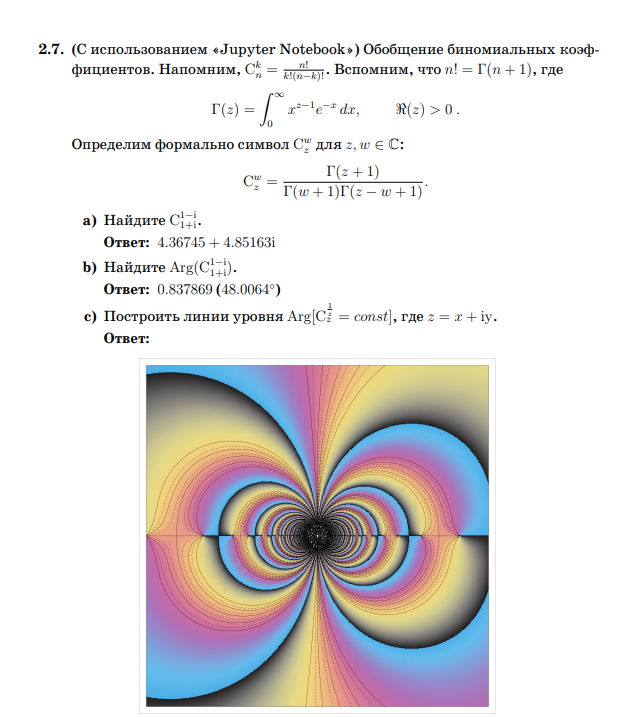

##  Математическая база

### Гамма-функция Эйлера

Гамма-функция обобщает факториал на комплексные числа:

$$\Gamma(z) = \int_0^\infty x^{z-1} e^{-x} \, dx, \quad \Re(z) > 0$$

**Ключевые свойства:**

| Свойство | Формула |
|:---:|:---|
| Связь с факториалом | $\Gamma(n+1) = n!$ для $n \in \mathbb{N}$ |
| Рекуррентное соотношение | $\Gamma(z+1) = z\,\Gamma(z)$ |
| Значение в 1/2 | $\Gamma(1/2) = \sqrt{\pi}$ |
| Формула дополнения | $\Gamma(z)\Gamma(1-z) = \dfrac{\pi}{\sin(\pi z)}$ |

### Обобщённые биномиальные коэффициенты

Для комплексных $z, w \in \mathbb{C}$:

$$C_z^w = \binom{z}{w} = \frac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}$$

При целых неотрицательных значениях это сводится к классической формуле:
$$C_n^k = \frac{n!}{k!(n-k)!}$$

### Аргумент комплексного числа

Для $z = re^{i\varphi}$:
$$\text{Arg}(z) = \varphi = \text{atan2}(\text{Im}(z), \text{Re}(z)) \in (-\pi, \pi]$$



a) C_{1+i}^{1-i} = 4.367449 + 4.851630i
b) Arg = 0.837869 рад = 48.0064°


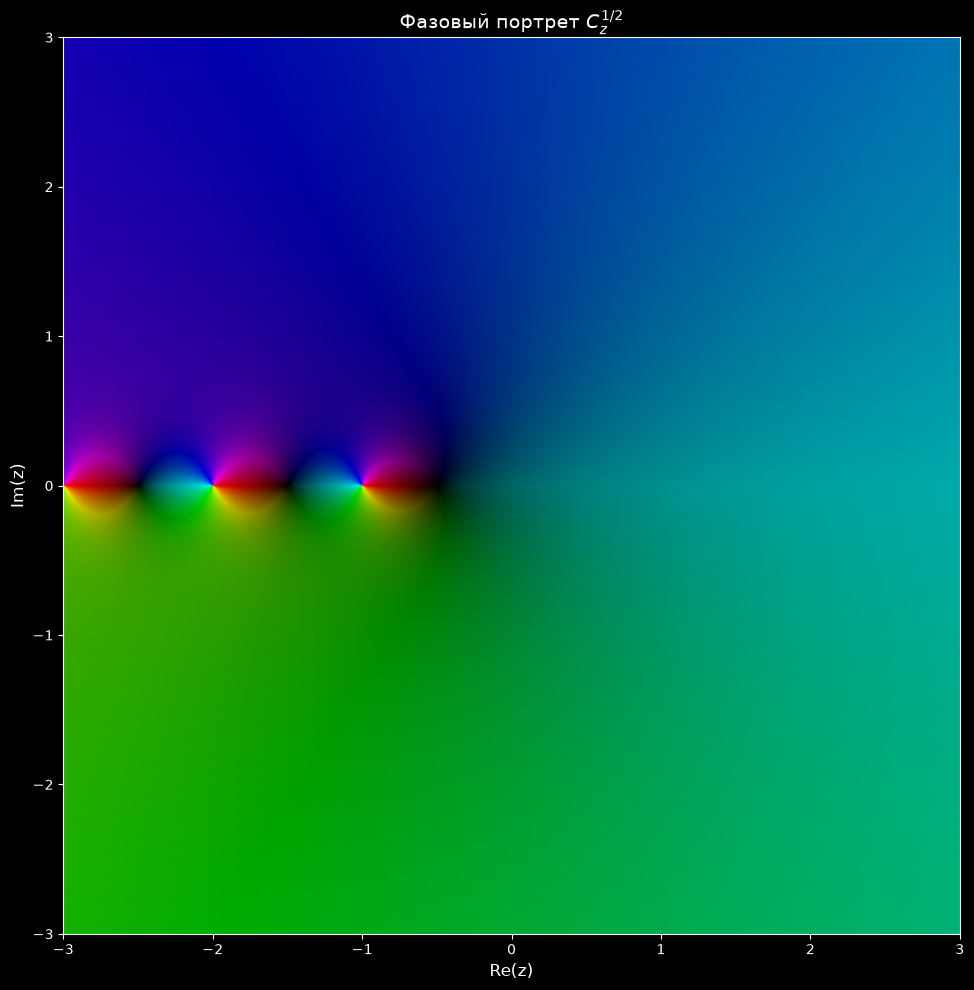

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import loggamma
from matplotlib.colors import hsv_to_rgb

# ────────────────────────────────────────────────────────
# a) и b) — численные значения
# ────────────────────────────────────────────────────────
z = 1 + 1j
w = 1 - 1j
log_C = loggamma(z + 1) - loggamma(w + 1) - loggamma(z - w + 1)
C = np.exp(log_C)

print(f"a) C_{{1+i}}^{{1-i}} = {C.real:.6f} + {C.imag:.6f}i")
print(f"b) Arg = {np.angle(C):.6f} рад = {np.degrees(np.angle(C)):.4f}°")

# ─────────────────────────────────────────────────────────
# c) Фазовый портрет C_z^{1/2}
# ─────────────────────────────────────────────────────────
N = 1000
x = np.linspace(-3, 3, N)
y = np.linspace(-3, 3, N)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

# C_z^{1/2} = Gamma(z+1) / (Gamma(3/2) * Gamma(z+1/2))
gamma_32 = np.sqrt(np.pi) / 2

# Работаем в логарифмической шкале для стабильности
log_num = loggamma(Z + 1)
log_den = np.log(gamma_32) + loggamma(Z + 0.5)
log_C_half = log_num - log_den

# Аргумент = мнимая часть логарифма
arg_val = np.imag(log_C_half)

# Модуль = exp(вещественная часть логарифма)
log_mag = np.real(log_C_half)

# ── Ключевое исправление: логарифмическая яркость ──
# Вместо magnitude/max используем сигмоиду от логарифма модуля
# Это позволяет видеть структуру на всём диапазоне значений
brightness = 1.0 / (1.0 + np.exp(-log_mag))  # сигмоида: 0..1

# Обработка NaN/Inf (полюса гамма-функции)
brightness = np.nan_to_num(brightness, nan=0.0, posinf=1.0, neginf=0.0)
arg_val = np.nan_to_num(arg_val, nan=0.0, posinf=0.0, neginf=0.0)

# HSV: оттенок = аргумент, насыщенность = 1, яркость = сигмоида(log|C|)
hsv = np.zeros((N, N, 3))
hsv[:, :, 0] = (arg_val + np.pi) / (2 * np.pi)  # оттенок [0, 1]
hsv[:, :, 1] = 1.0                                # насыщенность
hsv[:, :, 2] = brightness                         # яркость

rgb = hsv_to_rgb(hsv)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(rgb, extent=[-3, 3, -3, 3], origin='lower')
ax.set_title(r'Фазовый портрет $C_z^{1/2}$', fontsize=14)
ax.set_xlabel('Re(z)', fontsize=12)
ax.set_ylabel('Im(z)', fontsize=12)
plt.tight_layout()
plt.savefig('task_2_7_fixed.png', dpi=150)
plt.show()